*italicized text*# TASK 2: Exploratory Data Analysis (EDA)

## Project: Titanic Dataset Analysis

### Objective
The objective of this project is to explore the Titanic dataset, understand its structure, identify missing values and outliers, analyze trends and patterns, visualize relationships between variables, and test statistical hypotheses.

### Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn
- SciPy

### Project Workflow
1. Load the dataset.
2. Explore dataset structure and data types.
3. Ask meaningful analytical questions.
4. Check data quality.
5. Perform statistical analysis.
6. Create visualizations.
7. Test a hypothesis.
8. Identify data issues.
9. Write findings and conclusions.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

from scipy.stats import chi2_contingency

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:

from google.colab import files

# Find a previously uploaded Titanic file
candidates = [
    f for f in glob.glob("/content/*")
    if os.path.isfile(f)
    and os.path.basename(f).lower().startswith("titanic")
    and not f.lower().endswith((".ipynb", ".zip"))
]

if candidates:
    file_path = candidates[0]
    print("Using existing file:", os.path.basename(file_path))
else:
    print("Select your Titanic CSV file to upload.")
    uploaded = files.upload()

    if not uploaded:
        raise ValueError("No file was uploaded.")

    file_path = next(iter(uploaded))

# Read the CSV file
df = pd.read_csv(file_path)

print("\nDataset loaded successfully!")
print("File name:", os.path.basename(file_path))
print("Dataset shape:", df.shape)

display(df.head())


Select your Titanic CSV file to upload.


Saving titanic.csv to titanic.csv

Dataset loaded successfully!
File name: titanic.csv
Dataset shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:

display(df.head())


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:

display(df.tail())


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [ ]:

print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])
print("Dataset dimensions:", df.shape)


Total rows: 891
Total columns: 15
Dataset dimensions: (891, 15)


In [ ]:

print("Column names:")
print(df.columns.tolist())


Column names:
['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [ ]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [ ]:

display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Research Questions

Before analyzing the dataset, the following questions were formulated:

1. What proportion of passengers survived the Titanic disaster?
2. Did survival rates differ by sex?
3. Did passenger class have an association with survival?
4. How was passenger age distributed?
5. How did ticket fares vary among passengers?
6. Which columns contain missing values?
7. Are there duplicate records or unusual numerical values?
8. Is there a statistical association between sex and survival?
9. What data quality issues should be addressed before further analysis?

In [ ]:

missing_counts = df.isnull().sum()

print("Missing values in each column:")
display(missing_counts.to_frame("Missing Values"))


Missing values in each column:


,Missing Values
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [ ]:

missing_report = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_report.sort_values(
        by="Missing Percentage",
        ascending=False
    )
)


,Missing Values,Missing Percentage
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
sex,0,0.00
pclass,0,0.00
survived,0,0.00
fare,0,0.00
parch,0,0.00
sibsp,0,0.00


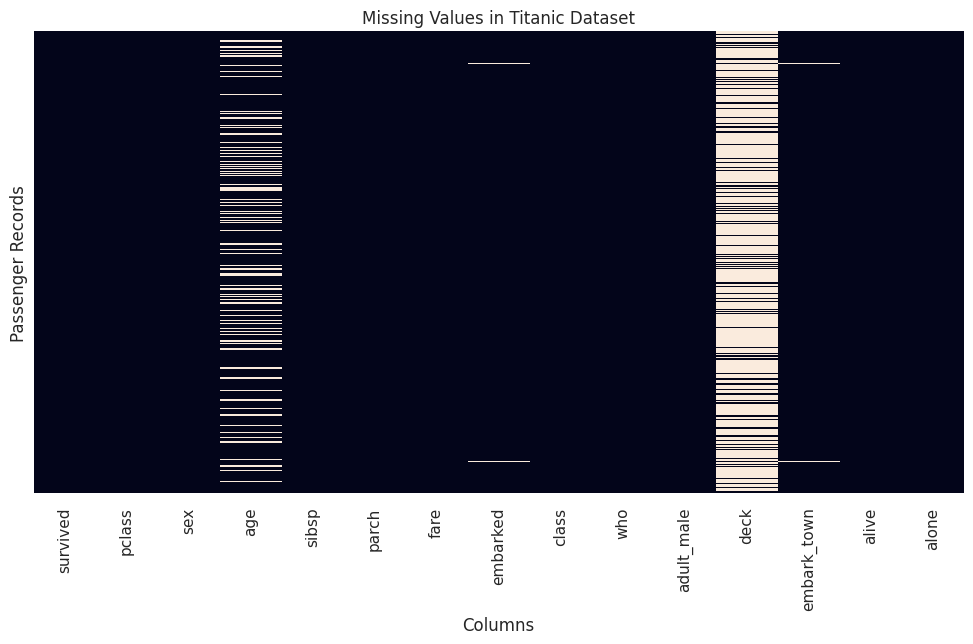

In [ ]:

plt.figure(figsize=(12, 6))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Columns")
plt.ylabel("Passenger Records")
plt.show()


In [ ]:

print("Total duplicate rows:", df.duplicated().sum())


Total duplicate rows: 107


In [ ]:

numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)


Numerical columns: ['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']
Categorical columns: ['sex', 'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town', 'alive', 'alone']


In [ ]:

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique values:", df[col].nunique())
    print(df[col].value_counts(dropna=False).head(10))



Column: sex
Unique values: 2
sex
male      577
female    314
Name: count, dtype: int64

Column: embarked
Unique values: 3
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

Column: class
Unique values: 3
class
Third     491
First     216
Second    184
Name: count, dtype: int64

Column: who
Unique values: 3
who
man      537
woman    271
child     83
Name: count, dtype: int64

Column: adult_male
Unique values: 2
adult_male
True     537
False    354
Name: count, dtype: int64

Column: deck
Unique values: 7
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64

Column: embark_town
Unique values: 3
embark_town
Southampton    644
Cherbourg      168
Queenstown      77
NaN              2
Name: count, dtype: int64

Column: alive
Unique values: 2
alive
no     549
yes    342
Name: count, dtype: int64

Column: alone
Unique values: 2
alone
True     537
False    354
Name: count, dtype: int64


In [ ]:

if "Survived" in df.columns:
    print("Survival counts:")
    display(df["Survived"].value_counts(dropna=False))

    print("\nSurvival percentages:")
    display(
        (df["Survived"].value_counts(normalize=True) * 100)
        .round(2)
    )
else:
    print("The Survived column is not present.")


The Survived column is not present.


In [ ]:

if "Survived" in df.columns:
    plt.figure(figsize=(7, 5))

    sns.countplot(data=df, x="Survived")

    plt.title("Survival Distribution")
    plt.xlabel("Survived (0 = No, 1 = Yes)")
    plt.ylabel("Number of Passengers")
    plt.show()


In [ ]:

if "Survived" in df.columns:
    survival_rate = df["Survived"].mean() * 100

    print(
        f"Overall survival rate: {survival_rate:.2f}%"
    )


In [ ]:

if {"Sex", "Survived"}.issubset(df.columns):
    survival_by_sex = (
        df.groupby("Sex", observed=True)["Survived"]
        .agg(["count", "mean"])
    )

    survival_by_sex["mean"] *= 100
    survival_by_sex.columns = [
        "Passenger Count", "Survival Rate (%)"
    ]

    display(survival_by_sex.round(2))

    plt.figure(figsize=(7, 5))
    sns.barplot(
        data=df, x="Sex", y="Survived",
        errorbar=None
    )

    plt.title("Survival Rate by Sex")
    plt.xlabel("Sex")
    plt.ylabel("Survival Rate")
    plt.show()


In [ ]:

if {"Pclass", "Survived"}.issubset(df.columns):
    survival_by_class = (
        df.groupby("Pclass", observed=True)["Survived"]
        .agg(["count", "mean"])
    )

    survival_by_class["mean"] *= 100
    survival_by_class.columns = [
        "Passenger Count", "Survival Rate (%)"
    ]

    display(survival_by_class.round(2))

    plt.figure(figsize=(7, 5))
    sns.barplot(
        data=df, x="Pclass", y="Survived",
        errorbar=None
    )

    plt.title("Survival Rate by Passenger Class")
    plt.xlabel("Passenger Class")
    plt.ylabel("Survival Rate")
    plt.show()


In [ ]:

if "Age" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df, x="Age",
        bins=25, kde=True
    )

    plt.title("Distribution of Passenger Ages")
    plt.xlabel("Age")
    plt.ylabel("Frequency")
    plt.show()


In [ ]:

if {"Age", "Survived"}.issubset(df.columns):
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df, x="Survived", y="Age"
    )

    plt.title("Age Distribution by Survival Status")
    plt.xlabel("Survived (0 = No, 1 = Yes)")
    plt.ylabel("Age")
    plt.show()

    display(
        df.groupby("Survived", observed=True)["Age"]
        .agg(["count", "mean", "median"])
        .round(2)
    )


In [ ]:

if "Fare" in df.columns:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df, x="Fare",
        bins=30, kde=True
    )

    plt.title("Distribution of Ticket Fares")
    plt.xlabel("Fare")
    plt.ylabel("Frequency")
    plt.show()


In [ ]:

if "Fare" in df.columns:
    plt.figure(figsize=(9, 4))

    sns.boxplot(data=df, x="Fare")

    plt.title("Boxplot of Ticket Fares")
    plt.xlabel("Fare")
    plt.show()


In [ ]:

if "Fare" in df.columns:
    print("Fare statistics:")
    display(
        df["Fare"].describe().to_frame().round(2)
    )


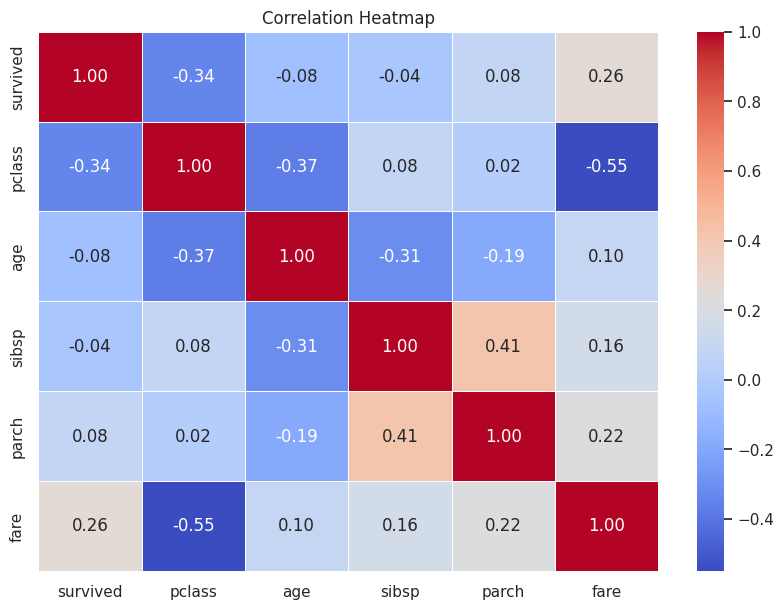

In [ ]:

numeric_df = df.select_dtypes(include=np.number)

if numeric_df.shape[1] >= 2:
    correlation_matrix = numeric_df.corr()

    plt.figure(figsize=(10, 7))

    sns.heatmap(
        correlation_matrix,
        annot=True,
        cmap="coolwarm",
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Correlation Heatmap")
    plt.show()
else:
    print("Not enough numerical columns for correlation.")


In [ ]:

if {"Sex", "Pclass", "Survived"}.issubset(df.columns):
    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=df,
        x="Pclass",
        y="Survived",
        hue="Sex",
        errorbar=None
    )

    plt.title("Survival Rate by Sex and Passenger Class")
    plt.xlabel("Passenger Class")
    plt.ylabel("Survival Rate")
    plt.show()


In [ ]:

outlier_results = []

for col in numerical_columns:
    values = df[col].dropna()

    if values.nunique() < 2:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outlier_count = (
        (values < lower_limit) |
        (values > upper_limit)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Potential Outliers": int(outlier_count)
    })

outlier_report = pd.DataFrame(outlier_results)

if not outlier_report.empty:
    display(outlier_report.round(2))
else:
    print("No suitable numerical columns were available.")


,Column,Lower Limit,Upper Limit,Potential Outliers
0,survived,-1.50,2.50,0
1,pclass,0.50,4.50,0
2,age,-6.69,64.81,11
3,sibsp,-1.50,2.50,46
4,parch,0.00,0.00,213
5,fare,-26.72,65.63,116


In [ ]:

if {"Sex", "Survived"}.issubset(df.columns):
    test_data = df[["Sex", "Survived"]].dropna()

    contingency_table = pd.crosstab(
        test_data["Sex"],
        test_data["Survived"]
    )

    print("Contingency Table:")
    display(contingency_table)

    if contingency_table.shape[0] >= 2 and contingency_table.shape[1] >= 2:
        chi2, p_value, dof, expected = chi2_contingency(
            contingency_table
        )

        print("Chi-square statistic:", round(chi2, 4))
        print("Degrees of freedom:", dof)
        print("P-value:", p_value)

        alpha = 0.05

        if p_value < alpha:
            print(
                "Decision: Reject H0. "
                "There is evidence of an association."
            )
        else:
            print(
                "Decision: Fail to reject H0. "
                "There is insufficient evidence of an association."
            )
    else:
        print("Insufficient categories for this test.")


In [ ]:

print("=" * 50)
print("TITANIC DATA QUALITY REPORT")
print("=" * 50)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Total missing cells:", int(df.isnull().sum().sum()))
print("Total duplicate rows:", int(df.duplicated().sum()))

print("\nColumns with missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nData types:")
print(df.dtypes)

print("\nNumerical columns with negative values:")
for col in numerical_columns:
    negative_count = int((df[col] < 0).sum())
    if negative_count > 0:
        print(col, ":", negative_count)


TITANIC DATA QUALITY REPORT
Number of rows: 891
Number of columns: 15
Total missing cells: 869
Total duplicate rows: 107

Columns with missing values:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64

Data types:
survived         int64
pclass           int64
sex             object
age            float64
sibsp            int64
parch            int64
fare           float64
embarked        object
class           object
who             object
adult_male        bool
deck            object
embark_town     object
alive           object
alone             bool
dtype: object

Numerical columns with negative values:


## Potential Data Quality Issues

The dataset was examined for the following potential issues:

1. Missing values in important variables.
2. Duplicate records that may require verification.
3. Potential outliers in numerical columns.
4. Incorrect or inconsistent data types.
5. Unexpected or inconsistent categorical values.
6. Invalid values that require domain-specific validation.

These issues should be investigated before further analysis. Missing values may be handled using appropriate imputation or exclusion strategies, depending on the variable and analysis objective. Duplicate records and outliers should be reviewed before deciding whether to remove or modify them.

The original dataset should be preserved so that all cleaning decisions remain traceable.

In [ ]:

print("=" * 55)
print("FINAL EDA SUMMARY")
print("=" * 55)

print(f"Total records: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")
print(f"Missing cells: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

if "Survived" in df.columns:
    print(
        f"Overall survival rate: "
        f"{df['Survived'].mean() * 100:.2f}%"
    )

if {"Sex", "Survived"}.issubset(df.columns):
    print("\nSurvival rate by sex (%):")
    print(
        (df.groupby("Sex", observed=True)["Survived"].mean() * 100)
        .round(2)
    )

if {"Pclass", "Survived"}.issubset(df.columns):
    print("\nSurvival rate by passenger class (%):")
    print(
        (df.groupby("Pclass", observed=True)["Survived"].mean() * 100)
        .round(2)
    )

print("\nSummary generated successfully.")


FINAL EDA SUMMARY
Total records: 891
Total columns: 15
Missing cells: 869
Duplicate rows: 107

Summary generated successfully.


# Conclusion

Exploratory Data Analysis was performed on the Titanic dataset using Python in Google Colab.

The dataset structure, variables, data types, descriptive statistics, missing values, and duplicate records were examined. Histograms, count plots, boxplots, bar plots, and a correlation heatmap were used to explore distributions and relationships among passenger characteristics.

The analysis investigated survival patterns by sex and passenger class, passenger age distributions, ticket fares, and potential outliers. A chi-square test was conducted to evaluate the association between sex and survival at a significance level of 0.05.

The data quality checks highlighted potential issues that should be reviewed before conducting further analysis. The results provide an initial understanding of the dataset and help identify useful directions for further statistical analysis or machine learning.

The final conclusions should be based on the numerical results and visualizations generated from the dataset.

